# Exploratory analysis: what the raw retail data looks like, and why the SQL does what it does

**Question this notebook answers.** Before building a retention analysis, what is wrong or surprising in the
Online Retail II transactions, and which of those things must the SQL layer handle?

Each section looks at one issue (missing values, distributions, outliers, returns, duplicates, non-product
lines), shows the evidence, and ends with the rule in `sql/` that it motivated. Every number here is computed
by a query or by code in this notebook. The cleaned results are in `docs/RESULTS.md`.

Data: UCI Online Retail II, UK online gift-ware retailer, December 2009 to December 2011, licence CC BY 4.0.
Revenue means quantity times price in pounds. It is not profit.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from retail import nb

nb.apply_style()
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 140
con = nb.connect()
P = nb.P
nb.banner()

## 1. Shape and coverage

In [2]:
shape = nb.sql(
    con,
    """SELECT count(*) AS rows, count(DISTINCT invoice_no) AS invoices,
              count(DISTINCT stock_code) AS stock_codes, count(DISTINCT customer_id) AS customers,
              count(DISTINCT country) AS countries,
              min(invoice_ts) AS first_timestamp, max(invoice_ts) AS last_timestamp
       FROM stg.transactions""",
)
display(shape.T.rename(columns={0: "value"}))
by_sheet = nb.sql(
    con,
    """SELECT sheet, count(*) AS rows, min(invoice_ts) AS first_timestamp, max(invoice_ts) AS last_timestamp
       FROM stg.transactions GROUP BY sheet ORDER BY sheet""",
)
display(by_sheet)

,value
rows,1067371
invoices,53628
stock_codes,5131
customers,5942
countries,43
first_timestamp,2009-12-01 07:45:00
last_timestamp,2011-12-09 12:50:00


,sheet,rows,first_timestamp,last_timestamp
0,Year 2009-2010,525461,2009-12-01 07:45:00,2010-12-09 20:01:00
1,Year 2010-2011,541910,2010-12-01 08:26:00,2011-12-09 12:50:00


The file is a workbook with two sheets, one per trading year. The date ranges above show the sheets do not
meet end to end: they **overlap**. That is checked properly in section 6.

| Column | Meaning | Type used in staging |
|---|---|---|
| Invoice | Invoice number; starts with C for a cancellation | text, plus a boolean flag |
| StockCode | Product code, with a few non-product codes mixed in | upper-cased text |
| Description | Product name | text, trimmed |
| Quantity | Units on the line; negative on cancellations | integer |
| InvoiceDate | Timestamp of the invoice | timestamp |
| Price | Unit price in pounds | DECIMAL(12,4) |
| Customer ID | Customer number; often empty | integer |
| Country | Country of the customer | text |

## 2. Missing values

,column_name,missing,total,missing_share
0,invoice_no,0,1067371,0.00
1,stock_code,0,1067371,0.00
2,description,4382,1067371,0.00
3,quantity,0,1067371,0.00
4,invoice_ts,0,1067371,0.00
5,unit_price,0,1067371,0.00
6,customer_id,243007,1067371,0.23
7,country,0,1067371,0.00


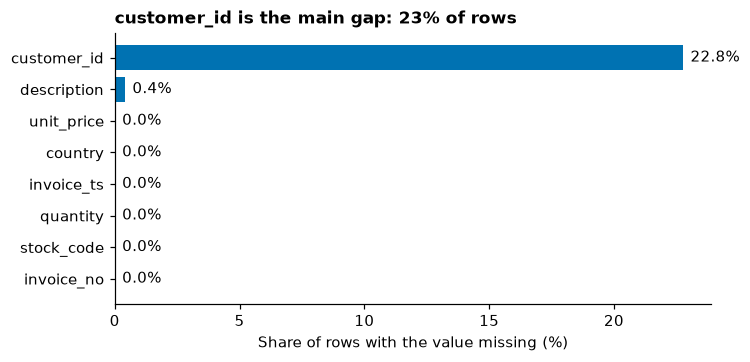

In [3]:
cols = [
    "invoice_no",
    "stock_code",
    "description",
    "quantity",
    "invoice_ts",
    "unit_price",
    "customer_id",
    "country",
]
parts = [
    f"SELECT '{c}' AS column_name, count(*) FILTER (WHERE {c} IS NULL OR trim({c}) = '') AS missing, count(*) AS total FROM raw.online_retail"
    for c in cols
]
miss = nb.sql(con, " UNION ALL ".join(parts))
miss["missing_share"] = miss.missing / miss.total
display(miss)

fig, ax = plt.subplots(figsize=(7, 3.2))
m = miss.sort_values("missing_share")
ax.barh(m.column_name, m.missing_share * 100, color=P["blue"])
for y, v in enumerate(m.missing_share * 100):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center")
ax.set_xlabel("Share of rows with the value missing (%)")
worst = miss.sort_values("missing_share").iloc[-1]
ax.set_title(f"{worst.column_name} is the main gap: {worst.missing_share:.0%} of rows")
plt.show()

,sheet,rows,share_rows_without_customer,share_revenue_without_customer
0,Year 2009-2010,521771,0.20,0.14
1,Year 2010-2011,539393,0.25,0.15


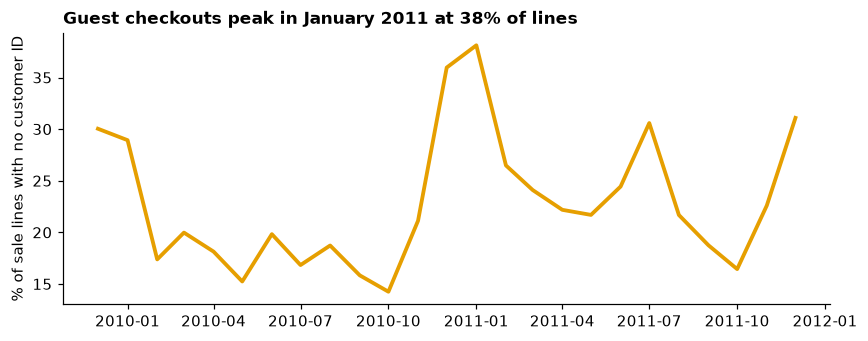

In [4]:
guest = nb.sql(
    con,
    """SELECT s.sheet, count(*) AS rows,
              avg(CAST(customer_id IS NULL AS INTEGER)) AS share_rows_without_customer,
              sum(line_value) FILTER (WHERE customer_id IS NULL) / sum(line_value) AS share_revenue_without_customer
       FROM stg.transactions s WHERE quantity > 0 AND unit_price > 0 OR is_cancellation GROUP BY s.sheet ORDER BY s.sheet""",
)
display(guest)
trend = nb.sql(
    con,
    """SELECT date_trunc('month', invoice_ts) AS month,
              avg(CAST(customer_id IS NULL AS INTEGER)) AS guest_row_share
       FROM stg.transactions WHERE quantity > 0 AND unit_price > 0 GROUP BY 1 ORDER BY 1""",
)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(trend.month, trend.guest_row_share * 100, color=P["orange"], lw=2.5)
ax.set_ylabel("% of sale lines with no customer ID")
hi = trend.loc[trend.guest_row_share.idxmax()]
ax.set_title(f"Guest checkouts peak in {hi.month:%B %Y} at {hi.guest_row_share:.0%} of lines")
plt.show()

**What this means.** Customer ID is the only column with a large gap, and the gap is not constant: the share of
lines without one swings from month to month (chart above). Rows without a customer cannot be followed over
time, so they cannot be part of cohorts or RFM, but they are real sales and must stay in revenue. That is the
rule in `sql/22_dq_log.sql` (`missing_customer_id`: kept and flagged) and the reason customer KPIs and revenue
KPIs are defined separately in `docs/KPI_DEFINITIONS.md`.

## 3. Distributions

,p1,p25,median,p75,p99,p99.9,max
quantity,1.00,1.00,3.00,10.00,100.00,485.98,"80,995.00"
unit_price,0.29,1.25,2.10,4.13,18.00,159.28,"25,111.09"
line_value,0.65,3.90,9.96,17.70,183.60,840.24,"168,469.60"


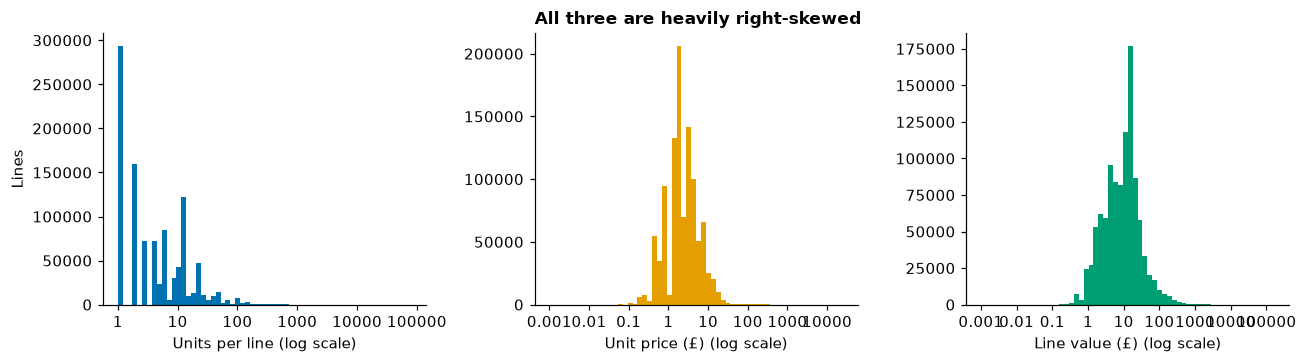

In [5]:
sales = nb.sql(
    con,
    """SELECT quantity, unit_price, quantity * unit_price AS line_value
       FROM stg.transactions WHERE quantity > 0 AND unit_price > 0""",
)
pct = sales.quantile([0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).T
pct.columns = ["p1", "p25", "median", "p75", "p99", "p99.9"]
pct["max"] = sales.max()
display(pct)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, label, colour in zip(
    axes,
    ["quantity", "unit_price", "line_value"],
    ["Units per line", "Unit price (£)", "Line value (£)"],
    [P["blue"], P["orange"], P["green"]],
):
    ax.hist(np.log10(sales[col]), bins=60, color=colour)
    ticks = [t for t in range(-3, 6) if sales[col].min() <= 10**t <= sales[col].max() * 3]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{10.0**t:g}" for t in ticks])
    ax.set_xlabel(label + " (log scale)")
axes[0].set_ylabel("Lines")
axes[1].set_title("All three are heavily right-skewed")
plt.tight_layout()
plt.show()

In [6]:
orders = nb.sql(
    con,
    """SELECT invoice_no, sum(line_value) AS order_value, count(*) AS n_lines
       FROM clean.lines WHERE line_type = 'sale' GROUP BY invoice_no""",
)
display(
    Markdown(
        f"Across {len(orders):,} sale invoices the mean order value is **£{orders.order_value.mean():,.0f}** but the "
        f"median is **£{orders.order_value.median():,.0f}**, and the 99th percentile is "
        f"**£{orders.order_value.quantile(0.99):,.0f}**. The mean sits well above the median because a few very large "
        "orders pull it up, so the dashboard shows basket size as revenue per order and the memo avoids leaning on "
        "the mean alone."
    )
)
top_share = (
    orders.sort_values("order_value", ascending=False).order_value.cumsum()
    / orders.order_value.sum()
)
k = int(len(orders) * 0.01)
display(
    Markdown(
        f"The largest 1% of orders ({k:,} invoices) carry **{top_share.iloc[k - 1]:.0%}** of order revenue."
    )
)

Across 38,700 sale invoices the mean order value is **£492** but the median is **£301**, and the 99th percentile is **£4,009**. The mean sits well above the median because a few very large orders pull it up, so the dashboard shows basket size as revenue per order and the memo avoids leaning on the mean alone.

The largest 1% of orders (387 invoices) carry **17%** of order revenue.

**What this means.** Quantities and prices span several orders of magnitude (the retailer sells to wholesalers
as well as individuals), so means mislead and thresholds must be explicit. The cleaning rules therefore do not
trim by percentile; they remove only rows that are impossible or are not product sales, and large values are
flagged rather than dropped (section 4).

## 4. Outliers

In [7]:
big = nb.sql(
    con,
    """SELECT invoice_no, invoice_ts, stock_code, description, quantity, unit_price, customer_id, line_value
       FROM stg.transactions ORDER BY abs(quantity) DESC LIMIT 8""",
)
display(big)
thr = con.execute("SELECT large_qty_threshold FROM dq.params").fetchone()[0]
flag = nb.sql(
    con,
    """SELECT count(*) AS lines_flagged,
              sum(line_value) FILTER (WHERE line_type = 'sale') AS flagged_sales,
              sum(line_value) FILTER (WHERE line_type = 'return') AS flagged_returns,
              (SELECT sum(line_value) FROM clean.lines) AS total_net_revenue
       FROM clean.lines WHERE is_large_quantity""",
).iloc[0]
display(
    Markdown(
        f"With a threshold of {thr:,} units there are **{int(flag.lines_flagged)}** flagged lines in the cleaned data. "
        f"They carry £{flag.flagged_sales:,.0f} of sales and £{abs(flag.flagged_returns):,.0f} of returns, "
        f"which is **{(flag.flagged_sales + flag.flagged_returns) / flag.total_net_revenue:.2%}** of net revenue."
    )
)

,invoice_no,invoice_ts,stock_code,description,quantity,unit_price,customer_id,line_value
0,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446,"168,469.60"
1,C581484,2011-12-09 09:27:00,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446,"-168,469.60"
2,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346,"77,183.60"
3,C541433,2011-01-18 10:17:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346,"-77,183.60"
4,497946,2010-02-15 11:57:00,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902,"1,915.20"
5,501534,2010-03-17 13:09:00,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902,"1,296.00"
6,501534,2010-03-17 13:09:00,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902,"1,296.00"
7,501534,2010-03-17 13:09:00,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902,"1,274.40"


With a threshold of 5,000 units there are **36** flagged lines in the cleaned data. They carry £130,689 of sales and £79,360 of returns, which is **0.28%** of net revenue.

In [8]:
paired = nb.sql(
    con,
    """WITH big_sales AS (
           SELECT * FROM clean.lines WHERE is_large_quantity AND line_type = 'sale' AND customer_id IS NOT NULL
       )
       SELECT b.invoice_no, b.customer_id, b.stock_code, b.quantity AS sold_units,
              any_value(r.quantity) AS returned_units, b.line_value AS sold_value,
              any_value(r.invoice_date) - b.invoice_date AS days_to_return
       FROM big_sales b
       LEFT JOIN clean.lines r
         ON r.line_type = 'return' AND r.customer_id = b.customer_id AND r.stock_code = b.stock_code
        AND r.quantity = -b.quantity AND r.invoice_date BETWEEN b.invoice_date AND b.invoice_date + 30
       GROUP BY b.invoice_no, b.customer_id, b.stock_code, b.quantity, b.line_value, b.invoice_date
       ORDER BY b.line_value DESC""",
)
reversed_ = paired.returned_units.notna()
display(paired.head(8))
display(
    Markdown(
        f"**{int(reversed_.sum())} of the {len(paired)} large sale lines** from identified customers are reversed in full by the "
        "same customer within 30 days. Those pairs cancel out of net revenue, which is why the SQL keeps both sides "
        "and flags them instead of deleting the sale and leaving the cancellation behind."
    )
)

,invoice_no,customer_id,stock_code,sold_units,returned_units,sold_value,days_to_return
0,541431,12346,23166,74215,-74215,"77,183.60",0
1,530715,15838,84347,9360,-9360,"15,818.40",28
2,498152,13902,85220,9456,<NA>,"2,836.80",<NA>
3,508748,17940,21985,5000,<NA>,"2,500.00",<NA>
4,502269,17940,21981,10000,<NA>,"2,500.00",<NA>
5,502269,17940,21980,10000,<NA>,"2,500.00",<NA>
6,502269,17940,21982,10000,<NA>,"2,500.00",<NA>
7,508748,17940,21982,5000,<NA>,"2,500.00",<NA>


**2 of the 31 large sale lines** from identified customers are reversed in full by the same customer within 30 days. Those pairs cancel out of net revenue, which is why the SQL keeps both sides and flags them instead of deleting the sale and leaving the cancellation behind.

**What this means.** The very largest quantities include order mistakes that were reversed on a later invoice
(the table above shows which large sales have a matching return). Dropping only the sale would overstate returns;
dropping only the cancellation would overstate sales. Keeping both nets them to zero. The other large lines
look like genuine wholesale orders, so the rule (`large_quantity_kept` in `sql/22_dq_log.sql`) flags them for
review and keeps them. The sensitivity above shows how little net revenue the flagged lines carry.

## 5. A first look at returns

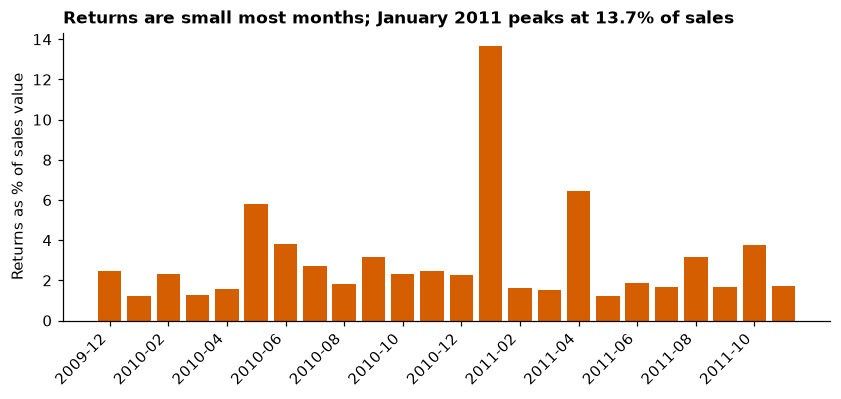

Cancellation invoices are **15.8%** of all invoices (7,269 of 45,969).

In [9]:
monthly = nb.sql(
    con, "SELECT month, sales_revenue, returns_value, return_rate FROM mart.monthly ORDER BY month"
)
ret_inv = nb.sql(
    con,
    """SELECT count(*) FILTER (WHERE order_type = 'return') AS return_invoices,
              count(*) AS invoices,
              count(*) FILTER (WHERE order_type = 'return') * 1.0 / count(*) AS return_invoice_share
       FROM mart.orders""",
).iloc[0]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(monthly.month.astype(str).str[:7], monthly.return_rate * 100, color=P["vermillion"])
ax.set_xticks(range(0, len(monthly), 2))
ax.set_xticklabels(monthly.month.astype(str).str[:7].iloc[::2], rotation=45, ha="right")
ax.set_ylabel("Returns as % of sales value")
peak = monthly.loc[monthly.return_rate.idxmax()]
ax.set_title(
    f"Returns are small most months; {peak.month:%B %Y} peaks at {peak.return_rate:.1%} of sales"
)
plt.show()
display(
    Markdown(
        f"Cancellation invoices are **{ret_inv.return_invoice_share:.1%}** of all invoices ({int(ret_inv.return_invoices):,} of "
        f"{int(ret_inv.invoices):,})."
    )
)

In [10]:
prod = nb.sql(
    con,
    """SELECT stock_code, description, sales_revenue, returns_value, return_rate
       FROM mart.products WHERE sales_revenue >= 20000 ORDER BY return_rate DESC LIMIT 8""",
)
display(prod)
lag = nb.sql(
    con,
    """SELECT count(*) AS returns_from_identified_customers,
              avg(CAST(customer_id IS NULL AS INTEGER)) AS share_without_customer
       FROM clean.lines WHERE line_type = 'return' """,
).iloc[0]
display(
    Markdown(
        f"Of **{int(lag.returns_from_identified_customers):,}** return lines in the cleaned data, "
        f"{lag.share_without_customer:.1%} have no customer ID, so almost all returns can be attributed to a customer. "
        "The file does not say which invoice a return belongs to, so a return cannot be tied back to its original sale."
    )
)

,stock_code,description,sales_revenue,returns_value,return_rate
0,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,448.21","-77,479.64",0.95
1,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,"25,186.85","-6,576.57",0.26
2,71477,COLOUR GLASS. STAR T-LIGHT HOLDER,"43,052.51","-7,057.47",0.16
3,47566B,TEA TIME PARTY BUNTING,"27,559.80","-4,490.50",0.16
4,84078A,SET/4 WHITE RETRO STORAGE CUBES,"43,666.82","-5,187.65",0.12
5,48185,DOORMAT FAIRY CAKE,"45,616.59","-4,678.68",0.10
6,37449,CERAMIC CAKE STAND + HANGING CAKES,"22,303.45","-2,194.35",0.10
7,20971,PINK BLUE FELT CRAFT TRINKET BOX,"28,122.81","-2,739.32",0.10


Of **17,568** return lines in the cleaned data, 1.9% have no customer ID, so almost all returns can be attributed to a customer. The file does not say which invoice a return belongs to, so a return cannot be tied back to its original sale.

**What this means.** Returns are a small share of sales in most months. The spikes trace back to a single
customer or invoice (the reversed order from section 4 is the largest), not to a general rise, and one product
is almost entirely returned for that reason. The SQL therefore keeps cancellation invoices as **negative revenue
on the date of cancellation** (`return_lines_kept`), defines revenue as net of returns, and defines an active
customer by purchases only, so a return does not make someone "active". The limitation is stated in the README:
returns cannot be matched to the original order.

## 6. Duplicates and the overlap between the sheets

In [11]:
ov = nb.sql(
    con,
    """WITH inv AS (SELECT invoice_no, count(DISTINCT sheet) AS n FROM stg.transactions GROUP BY invoice_no)
       SELECT count(*) FILTER (WHERE n > 1) AS invoices_in_both_sheets,
              count(*) AS invoices FROM inv""",
).iloc[0]
same = nb.sql(
    con,
    """WITH both_inv AS (SELECT invoice_no FROM stg.transactions GROUP BY invoice_no HAVING count(DISTINCT sheet) > 1),
            a AS (SELECT invoice_no, stock_code, description, quantity, invoice_ts, unit_price, customer_id, country
                  FROM stg.transactions WHERE invoice_no IN (SELECT invoice_no FROM both_inv)
                    AND sheet = (SELECT min(sheet) FROM stg.transactions)),
            b AS (SELECT invoice_no, stock_code, description, quantity, invoice_ts, unit_price, customer_id, country
                  FROM stg.transactions WHERE invoice_no IN (SELECT invoice_no FROM both_inv)
                    AND sheet = (SELECT max(sheet) FROM stg.transactions))
       SELECT (SELECT count(*) FROM a) AS lines_in_first_sheet, (SELECT count(*) FROM b) AS lines_in_second_sheet,
              (SELECT count(*) FROM (SELECT * FROM a EXCEPT ALL SELECT * FROM b)) AS only_in_first,
              (SELECT count(*) FROM (SELECT * FROM b EXCEPT ALL SELECT * FROM a)) AS only_in_second""",
).iloc[0]
display(
    Markdown(
        f"**{int(ov.invoices_in_both_sheets):,}** invoices appear in both sheets ({int(same.lines_in_first_sheet):,} lines in the first, "
        f"{int(same.lines_in_second_sheet):,} in the second). Lines that differ between the copies: "
        f"**{int(same.only_in_first)}** only in the first, **{int(same.only_in_second)}** only in the second."
    )
)
log = nb.sql(
    con,
    "SELECT rule, n_rows, revenue FROM dq.rule_log WHERE rule IN ('cross_sheet_overlap_copy', 'exact_duplicate_line')",
)
display(log)

**1,088** invoices appear in both sheets (22,523 lines in the first, 22,523 in the second). Lines that differ between the copies: **0** only in the first, **0** only in the second.

,rule,n_rows,revenue
0,cross_sheet_overlap_copy,22523,"377,488.45"
1,exact_duplicate_line,11812,"54,228.42"


**What this means.** The copies are identical, so keeping both would double count a block of days and inflate
December 2010. The SQL drops the later sheet's copy (`cross_sheet_overlap_copy`). Separately, some lines
repeat exactly within an invoice. They are treated as double entries and dropped (`exact_duplicate_line`); a
genuine repeat scan would also be dropped, which is why that rule's effect on revenue is reported rather than
hidden.

## 7. Lines that are not product sales

In [12]:
nm = nb.sql(
    con,
    """SELECT non_merch_type, count(*) AS rows, sum(line_value) AS revenue, min(stock_code) AS example_code
       FROM stg.transactions_flagged WHERE non_merch_type IS NOT NULL AND dq_reason = 'non_merchandise_charge'
       GROUP BY 1 ORDER BY abs(sum(line_value)) DESC""",
)
display(nm)
sc = nb.sql(
    con,
    """SELECT quantity < 0 AS negative_quantity, NOT is_cancellation AS normal_invoice, unit_price = 0 AS zero_price,
              customer_id IS NULL AS no_customer, count(*) AS rows
       FROM stg.transactions_flagged WHERE dq_reason = 'sign_conflict' GROUP BY ALL ORDER BY rows DESC""",
)
display(sc)

,non_merch_type,rows,revenue,example_code
0,postage_carriage,3788,"433,410.51",C2
1,platform_or_bank_fee,152,"-264,936.18",AMAZONFEE
2,manual_discount_or_adjustment,1742,"-242,229.81",ADJUST
3,gift_voucher,100,"1,686.61",GIFT_0001_10
4,test_product,17,203.50,TEST001


,negative_quantity,normal_invoice,zero_price,no_customer,rows
0,True,True,True,True,3393


**What this means.** Postage, fees, manual adjustments, bad-debt entries, gift vouchers and test products sit in
the same column as products. Several carry large negative values, so leaving them in would make revenue
unreliable and product rankings meaningless. They are removed from merchandise revenue (`non_merchandise_charge`)
and shown in the revenue bridge so nothing disappears silently. Negative quantities on normal invoices are
zero-price stock write-offs with no customer in this file (table above), not sales, and are removed under `sign_conflict`.

## 8. From findings to rules, and a reconciliation

In [13]:
rules = nb.sql(
    con,
    "SELECT rule_order, rule, kind, n_rows, share_of_raw_rows FROM dq.rule_log ORDER BY rule_order",
)
rules["share_of_raw_rows"] = (rules.share_of_raw_rows * 100).round(2).astype(str) + "%"
display(rules)
bridge = nb.sql(con, "SELECT step, label, n_rows, revenue FROM mart.revenue_bridge ORDER BY step")
display(bridge)
raw_rows = con.execute("SELECT count(*) FROM raw.online_retail").fetchone()[0]
kept = con.execute("SELECT count(*) FROM clean.lines").fetchone()[0]
excluded = con.execute("SELECT sum(n_rows) FROM dq.rule_log WHERE kind = 'excluded'").fetchone()[0]
assert kept + excluded == raw_rows, "row bridge does not reconcile"
raw_rev = con.execute("SELECT sum(quantity * unit_price) FROM stg.transactions").fetchone()[0]
bridge_total = bridge.revenue.iloc[:-1].sum()
assert abs(float(bridge_total) - float(bridge.revenue.iloc[-1])) < 0.01, (
    "revenue bridge does not reconcile"
)
display(
    Markdown(
        f"Reconciled: {raw_rows:,} raw rows = {kept:,} kept + {int(excluded):,} removed, and the revenue bridge adds up to "
        f"£{float(bridge.revenue.iloc[-1]):,.2f} of kept revenue."
    )
)

,rule_order,rule,kind,n_rows,share_of_raw_rows
0,1,cross_sheet_overlap_copy,excluded,22523,2.11%
1,2,exact_duplicate_line,excluded,11812,1.11%
2,3,non_merchandise_charge,excluded,5799,0.54%
3,4,unparseable_or_zero_quantity,excluded,0,0.0%
4,5,sign_conflict,excluded,3393,0.32%
5,6,nonpositive_price,excluded,2572,0.24%
6,7,outside_analysis_window,excluded,25100,2.35%
7,10,missing_customer_id,kept_and_flagged,219299,20.55%
8,11,return_lines_kept,kept_and_flagged,17568,1.65%
9,12,large_quantity_kept,kept_and_flagged,36,0.0%


,step,label,n_rows,revenue
0,0,raw file,1067371,"19,287,250.57"
1,1,cross_sheet_overlap_copy,-22523,"-377,488.45"
2,2,exact_duplicate_line,-11812,"-54,228.42"
3,3,non_merchandise_charge,-5799,"71,865.37"
4,4,unparseable_or_zero_quantity,0,0.00
5,5,sign_conflict,-3393,0.00
6,6,nonpositive_price,-2572,0.00
7,7,outside_analysis_window,-25100,"-440,399.56"
8,99,kept (clean.lines),996172,"18,486,999.51"


Reconciled: 1,067,371 raw rows = 996,172 kept + 71,199 removed, and the revenue bridge adds up to £18,486,999.51 of kept revenue.

## 9. A first look at the three business questions

These charts motivated the marts in `sql/30_` to `sql/36_`. The finished versions are in the dashboard
and in `docs/RESULTS.md`.

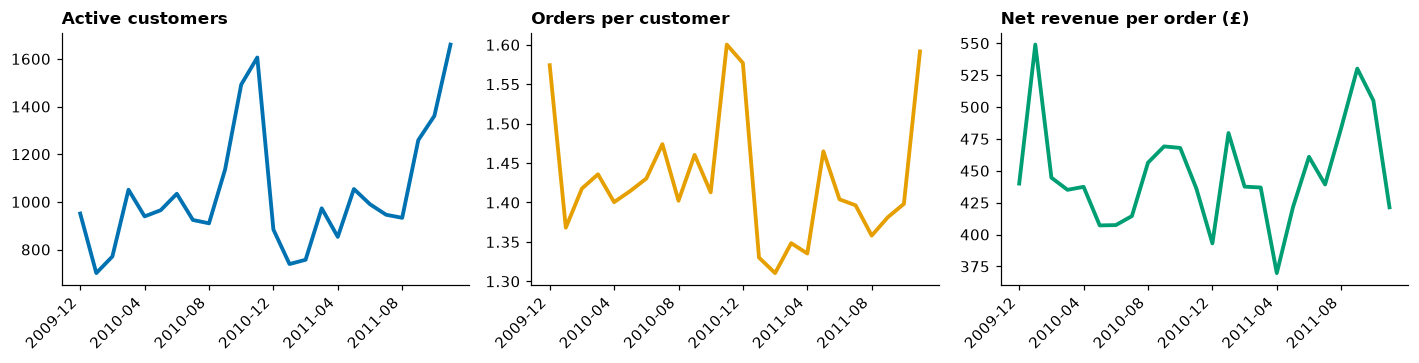

**28%** of identified customers bought exactly once, so how many come back, and who, is the question the cohort and RFM tables answer.

In [14]:
m = nb.sql(
    con,
    "SELECT month, net_revenue, active_customers, orders_per_customer, net_revenue_per_order FROM mart.monthly ORDER BY month",
)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
x = m.month.astype(str).str[:7]
for ax, col, label, colour in zip(
    axes,
    ["active_customers", "orders_per_customer", "net_revenue_per_order"],
    ["Active customers", "Orders per customer", "Net revenue per order (£)"],
    [P["blue"], P["orange"], P["green"]],
):
    ax.plot(x, m[col], color=colour, lw=2.5)
    ax.set_xticks(range(0, len(m), 4))
    ax.set_xticklabels(x.iloc[::4], rotation=45, ha="right")
    ax.set_title(label)
plt.tight_layout()
plt.show()
once = con.execute("SELECT one_order_share FROM mart.headline").fetchone()[0]
display(
    Markdown(
        f"**{once:.0%}** of identified customers bought exactly once, so how many come back, and who, is the question "
        "the cohort and RFM tables answer."
    )
)

## What is weak

- Missing customer IDs are not random, so customer-level results describe identified customers only.
- Duplicate removal cannot tell a double entry from a genuine repeat scan.
- Returns cannot be linked to the original sale, so a return is dated when it was cancelled, not when it was sold.
- Prices and quantities have no cost, margin or discount fields, so nothing here says anything about profit.
- One retailer, two years: seasonality is seen twice at most.